
# ILLM Lab 8 — Neural Machine Translation with OpenNMT-py: Length-Binned Evaluation

Builds an English→Hindi neural machine translation system with
[OpenNMT-py](https://github.com/OpenNMT/OpenNMT-py), trained on the **ILCI**
subset of [AI4Bharat's BPCC](https://huggingface.co/datasets/ai4bharat/BPCC)
parallel corpus, with train/test splits built by **length-stratified
binning** (not random sampling), and evaluated with **bin-wise
[sacrebleu](https://github.com/mjpost/sacrebleu) BLEU scores**.

---

## 1. Deep analysis of the assignment

| # | Requirement | What it means concretely |
|---|---|---|
| 1 | Parallel sentences, BPCC `ilci` subset, English source / native-language target | English→Hindi pairs from `ai4bharat/BPCC`, config `ilci`. **This dataset is gated** on HuggingFace — see the prerequisite note below. |
| 2 | Train/test split **by length bins, not random** | Every sentence pair is assigned to one of 4 bins by its **English (source) word count**; train and test are built by splitting *within* each bin, so both splits contain the same proportional mix of short and long sentences — a uniform random split could (by chance, or just because long sentences are rarer) under-represent a bin in test entirely. |
| 3 | 4 length bins, exact boundaries given | bin1 $\le 10$, bin2 $(10,20]$, bin3 $(20,30]$, bin4 $>30$ — read as closed/open the way the assignment's own notation implies (each boundary value belongs to exactly one bin, never two). |
| 4 | Design and train an NMT model with OpenNMT-py | A real `onmt_build_vocab` → `onmt_train` → `onmt_translate` pipeline, not a hand-rolled substitute — OpenNMT-py is CLI/YAML-config-driven, not a typical Python API, which shapes how this notebook invokes it (via `subprocess`, Section 6). |
| 5 | Evaluate with sacrebleu, **bin-wise** | Corpus BLEU computed **separately for each bin's test sentences**, not just one overall score — the entire point of binning the data in the first place is to be able to compare translation quality across sentence lengths. |

**Design decisions (stated explicitly, since the assignment leaves these open):**

- **Target language: Hindi (`hin_Deva`)** — the language used consistently
  across every earlier lab in this series.
- **`ai4bharat/BPCC` requires accepting its terms on HuggingFace before any
  download works** — visit
  [the dataset page](https://huggingface.co/datasets/ai4bharat/BPCC) while
  logged in, accept the conditions, then authenticate locally (`huggingface-cli login`
  or set the `HF_TOKEN` environment variable) **before running Section 2**.
  This is a real access-control requirement, not a detail this notebook can
  route around.
- **A small built-in fallback dataset** (synthetic English–Hindi pairs,
  clearly not real translations) is used if BPCC isn't reachable, purely so
  every cell in this notebook — binning, OpenNMT-py training, bin-wise
  BLEU — is runnable and demonstrably correct without your HuggingFace
  access being set up yet.
- **A small RNN encoder–decoder with attention, not a Transformer** — trained
  from scratch on CPU-scale compute (which is what most students actually
  have), an RNN of this size trains in minutes where a Transformer with
  comparable quality would need substantially more steps and compute to
  reach a comparable point. `MODEL_SIZE`/`TRAIN_STEPS` are both clearly
  marked, single-place config values — scale them up if you have a GPU and
  more time; this notebook is pedagogically scaled, not a production MT
  system. Swapping to a Transformer is a config change, noted at that point.
- **Length bins are computed on the English (source) side's word count**
  (plain whitespace split) — translation difficulty is driven primarily by
  what has to be *read and understood*, and this also keeps the binning
  criterion well-defined even before the target side exists (i.e. consistent
  with how you'd bin genuinely new, unlabeled source sentences at inference
  time).
- **BLEU uses sacrebleu's default tokenizer**, not the Devanagari-aware
  `flores200` SentencePiece tokenizer — `flores200` needs a one-time model
  download this notebook can't pre-verify in every environment; it's noted
  as an optional one-line upgrade at the point BLEU is computed (Section 8),
  since whitespace already delimits words correctly in Devanagari, the
  default tokenizer is a reasonable, workable default even though the
  SentencePiece-based one is arguably more linguistically apt.

## 2. Plan for this notebook

```
Load BPCC ilci (English-Hindi) -- real data if HF access is set up, else a demo fallback
        ▼
Bin every sentence pair by ENGLISH word count into bin1..bin4
        ▼
Within each bin independently, split into train/test (stratified, not global-random)
        ▼
Write OpenNMT-py's expected plain-text format: src-train.txt / tgt-train.txt / src-test.txt
        ▼
Write a YAML config (small RNN encoder-decoder) and run:
   onmt_build_vocab  -->  onmt_train  -->  onmt_translate
        ▼
Score with sacrebleu: overall BLEU, then BIN-WISE BLEU on the test set
        ▼
Qualitative examples per bin + bin-wise result analysis
```



## Section 1 — Environment Setup

> **A cosmetic (non-fatal) warning, not a real error:** OpenNMT-py's
> installed build prints a `UserWarning: Failed to initialize NumPy` /
> `A module that was compiled using NumPy 1.x cannot be run in NumPy 2.x`
> message on import, on some environments. This was confirmed, while
> building this notebook, to **not** actually break vocab building,
> training, or translation — it's noisy, not fatal. If a real failure
> happens downstream (not just this warning), pinning `numpy<2` is the
> standard fix for this class of issue (see Labs 6–7 for the same pattern
> with other libraries).


In [1]:

# !pip install --quiet OpenNMT-py sacrebleu sentencepiece datasets


In [2]:

import os
import re
import random
import subprocess
import time
from collections import defaultdict

import pandas as pd
import sacrebleu

RANDOM_SEED = 42
random.seed(RANDOM_SEED)

SRC_LANG, TGT_LANG = "eng_Latn", "hin_Deva"
WORK_DIR = "nmt_lab8"
os.makedirs(WORK_DIR, exist_ok=True)

print("Environment ready.")


Environment ready.



## Section 2 — Load BPCC `ilci` (English–Hindi)

**Prerequisite (see Section 1's note):** `ai4bharat/BPCC` is gated — accept
its terms on the [dataset page](https://huggingface.co/datasets/ai4bharat/BPCC)
and authenticate locally first, or this cell's real-data branch will raise an
authentication error and fall back to the demo data below instead.


In [3]:

def load_bpcc_ilci(src_lang, tgt_lang):
    """Real BPCC ilci loader. The exact config-naming convention couldn't be
    verified against the live (gated) repo while building this notebook, so
    this tries the most likely pattern first and reports the real error if
    it doesn't match your copy of the dataset -- adjust `data_dir`/the config
    name below based on what that error (or the HF dataset viewer) shows."""
    from datasets import load_dataset
    ds = load_dataset("ai4bharat/BPCC", "ilci", data_dir=f"{src_lang}-{tgt_lang}", split="train")
    pairs = []
    for row in ds:
        # Try the common field-name conventions for this family of datasets.
        src = row.get(f"sentence_{src_lang}") or row.get(src_lang) or row.get("src")
        tgt = row.get(f"sentence_{tgt_lang}") or row.get(tgt_lang) or row.get("tgt")
        if src and tgt:
            pairs.append((src, tgt))
    return pairs

def build_demo_parallel_data():
    """Small, clearly-synthetic English-Hindi pairs, spanning all 4 length
    bins by construction. NOT real translations -- a stand-in so the rest of
    this notebook (binning, OpenNMT-py, bin-wise BLEU) is fully runnable
    without your BPCC access being set up yet."""
    short_pairs = [
        ("The cat sat on the mat.", "बिल्ली चटाई पर बैठी।"),
        ("She went to the market.", "वह बाज़ार गई।"),
        ("This book is interesting.", "यह किताब दिलचस्प है।"),
        ("He plays football daily.", "वह रोज़ फुटबॉल खेलता है।"),
        ("The train is late today.", "ट्रेन आज देर से है।"),
        ("I would like some tea.", "मुझे कुछ चाय चाहिए।"),
        ("The weather is very pleasant.", "मौसम बहुत सुहावना है।"),
        ("They live near the river.", "वे नदी के पास रहते हैं।"),
    ]
    medium_pairs = [
        ("The company declined to comment on the matter raised by reporters.",
         "कंपनी ने पत्रकारों द्वारा उठाए गए मामले पर टिप्पणी करने से इनकार कर दिया।"),
        ("Doctors recommend regular exercise and a balanced diet for good health.",
         "डॉक्टर अच्छे स्वास्थ्य के लिए नियमित व्यायाम और संतुलित आहार की सलाह देते हैं।"),
        ("The government announced a new policy to support small businesses.",
         "सरकार ने छोटे व्यवसायों का समर्थन करने के लिए एक नई नीति की घोषणा की।"),
        ("Tourists visiting the region should carry warm clothes and sturdy shoes.",
         "इस क्षेत्र में आने वाले पर्यटकों को गर्म कपड़े और मजबूत जूते साथ रखने चाहिए।"),
        ("The hospital has introduced a new system to reduce patient waiting times.",
         "अस्पताल ने मरीजों के प्रतीक्षा समय को कम करने के लिए एक नई प्रणाली शुरू की है।"),
        ("Farmers in the area have faced difficulties due to the unexpected rainfall.",
         "इस क्षेत्र के किसानों को अप्रत्याशित बारिश के कारण कठिनाइयों का सामना करना पड़ा है।"),
    ]
    long_pairs = [
        ("The committee, after reviewing the proposal in detail over several meetings, "
         "decided to approve the project but requested additional safety measures.",
         "समिति ने कई बैठकों में प्रस्ताव की विस्तार से समीक्षा करने के बाद, परियोजना को मंजूरी देने "
         "का निर्णय लिया लेकिन अतिरिक्त सुरक्षा उपायों का अनुरोध किया।"),
        ("Researchers have found that regular physical activity, combined with a healthy diet "
         "and adequate sleep, significantly reduces the risk of several chronic diseases.",
         "शोधकर्ताओं ने पाया है कि नियमित शारीरिक गतिविधि, स्वस्थ आहार और पर्याप्त नींद के साथ मिलकर, "
         "कई पुरानी बीमारियों के खतरे को काफी हद तक कम करती है।"),
        ("The annual conference, which brings together experts from across the country to "
         "discuss emerging trends in technology, education, and public policy, will be held "
         "next month in the capital.",
         "वार्षिक सम्मेलन, जो प्रौद्योगिकी, शिक्षा और सार्वजनिक नीति में उभरते रुझानों पर चर्चा करने के "
         "लिए देशभर के विशेषज्ञों को एक साथ लाता है, अगले महीने राजधानी में आयोजित किया जाएगा।"),
        ("Despite facing numerous challenges during the construction of the bridge, including "
         "unexpected delays due to weather conditions and material shortages, the engineering "
         "team managed to complete the project ahead of the revised deadline.",
         "पुल के निर्माण के दौरान कई चुनौतियों का सामना करने के बावजूद, जिसमें मौसम की स्थिति और "
         "सामग्री की कमी के कारण अप्रत्याशित देरी शामिल थी, इंजीनियरिंग टीम ने संशोधित समय सीमा से "
         "पहले ही परियोजना को पूरा करने में सफलता हासिल की।"),
    ]
    all_pairs = (short_pairs * 15) + (medium_pairs * 15) + (long_pairs * 15)
    random.Random(RANDOM_SEED).shuffle(all_pairs)
    return all_pairs

try:
    parallel_pairs = load_bpcc_ilci(SRC_LANG, TGT_LANG)
    if not parallel_pairs:
        raise ValueError("Loaded 0 pairs -- field names likely don't match this dataset's actual schema.")
    print(f"Loaded {len(parallel_pairs):,} real BPCC ilci English-Hindi pairs.")
except Exception as e:
    print("=" * 78)
    print(f"WARNING: could not load real BPCC ilci data ({type(e).__name__}: {e})")
    print("Using a small built-in DEMO parallel dataset instead -- see Section 1's")
    print("prerequisite note on HuggingFace authentication for the real dataset.")
    print("=" * 78)
    parallel_pairs = build_demo_parallel_data()

print(f"\nTotal pairs: {len(parallel_pairs):,}")
print("Example pair:", parallel_pairs[0])


Using a small built-in DEMO parallel dataset instead -- see Section 1's
prerequisite note on HuggingFace authentication for the real dataset.

Total pairs: 270
Example pair: ('The company declined to comment on the matter raised by reporters.', 'कंपनी ने पत्रकारों द्वारा उठाए गए मामले पर टिप्पणी करने से इनकार कर दिया।')



## Section 3 — Length Bins & Stratified Train/Test Split

Every pair is assigned a bin from its **English word count**:

| Bin | Condition |
|---|---|
| bin1 | length $\le 10$ |
| bin2 | $10 <$ length $\le 20$ |
| bin3 | $20 <$ length $\le 30$ |
| bin4 | length $> 30$ |

**The split happens separately within each bin**, not on the pooled data —
each bin is independently shuffled and divided `TEST_FRACTION`/rest, so train
and test both end up containing the *same proportional mix* of sentence
lengths as the full dataset. A single global random split could easily
under-represent bin4 in the test set purely because long sentences are rarer
to begin with — stratifying by bin is exactly what prevents that.


In [4]:

def assign_bin(src_text):
    length = len(src_text.split())
    if length <= 10:
        return "bin1 (<=10)"
    elif length <= 20:
        return "bin2 (10,20]"
    elif length <= 30:
        return "bin3 (20,30]"
    else:
        return "bin4 (>30)"

binned = defaultdict(list)
for src, tgt in parallel_pairs:
    binned[assign_bin(src)].append((src, tgt))

BIN_ORDER = ["bin1 (<=10)", "bin2 (10,20]", "bin3 (20,30]", "bin4 (>30)"]
for b in BIN_ORDER:
    print(f"{b:<15} {len(binned[b]):>8,} pairs")


bin1 (<=10)          135 pairs
bin2 (10,20]          75 pairs
bin3 (20,30]          45 pairs
bin4 (>30)            15 pairs


In [5]:

TEST_FRACTION = 0.1  # applied independently within each bin

train_pairs, test_pairs = [], []
train_bin_of, test_bin_of = [], []  # parallel lists recording which bin each pair came from

rng = random.Random(RANDOM_SEED)
for b in BIN_ORDER:
    pairs_in_bin = binned[b][:]
    rng.shuffle(pairs_in_bin)
    n_test = max(1, int(len(pairs_in_bin) * TEST_FRACTION)) if pairs_in_bin else 0
    bin_test = pairs_in_bin[:n_test]
    bin_train = pairs_in_bin[n_test:]
    train_pairs.extend(bin_train)
    test_pairs.extend(bin_test)
    train_bin_of.extend([b] * len(bin_train))
    test_bin_of.extend([b] * len(bin_test))
    print(f"{b:<15} train={len(bin_train):>7,}  test={len(bin_test):>6,}")

print(f"\nTotal train: {len(train_pairs):,}   Total test: {len(test_pairs):,}")


bin1 (<=10)     train=    122  test=    13
bin2 (10,20]    train=     68  test=     7
bin3 (20,30]    train=     41  test=     4
bin4 (>30)      train=     14  test=     1

Total train: 245   Total test: 25



## Section 4 — Write OpenNMT-py's Expected Data Format

Plain text, one sentence per line, source and target in separate files —
exactly the format the [OpenNMT-py quickstart](https://github.com/OpenNMT/OpenNMT-py/blob/master/docs/source/quickstart.md)
expects. `test_bin_of` is kept alongside the test files (not written into
them) so Section 8 can split sacrebleu scoring back out by bin afterward.


In [6]:

def write_parallel_files(pairs, src_path, tgt_path):
    with open(src_path, "w", encoding="utf-8") as fs, open(tgt_path, "w", encoding="utf-8") as ft:
        for src, tgt in pairs:
            fs.write(src.replace("\n", " ").strip() + "\n")
            ft.write(tgt.replace("\n", " ").strip() + "\n")

# A small validation slice carved out of train (OpenNMT-py needs a `valid` set
# during training, separate from the held-out test set used for BLEU).
_val_n = max(1, int(len(train_pairs) * 0.05))
valid_pairs = train_pairs[:_val_n]
fit_train_pairs = train_pairs[_val_n:]

write_parallel_files(fit_train_pairs, f"{WORK_DIR}/src-train.txt", f"{WORK_DIR}/tgt-train.txt")
write_parallel_files(valid_pairs, f"{WORK_DIR}/src-valid.txt", f"{WORK_DIR}/tgt-valid.txt")
write_parallel_files(test_pairs, f"{WORK_DIR}/src-test.txt", f"{WORK_DIR}/tgt-test.txt")

print(f"Training pairs (after carving out validation): {len(fit_train_pairs):,}")
print(f"Validation pairs: {len(valid_pairs):,}")
print(f"Test pairs: {len(test_pairs):,}")


Training pairs (after carving out validation): 233
Validation pairs: 12
Test pairs: 25



## Section 5 — OpenNMT-py Configuration

A small bidirectional-RNN encoder, attention-based RNN decoder — the
"default model" the OpenNMT-py quickstart itself describes, sized down
further for CPU-scale training. `TRAIN_STEPS` and the model-size variables
are the two things most worth raising first if you have a GPU and more time;
everything else in the pipeline is unaffected by that choice.

> **A real crash this config works around:** OpenNMT-py's default
> `num_workers: 2` spawns PyTorch `DataLoader` worker *subprocesses* for data
> loading. On a resource-constrained machine (few CPU cores, limited shared
> memory — a small cloud VM, a constrained container, some CI runners), those
> worker subprocesses can be killed outright, surfacing as
> `RuntimeError: DataLoader worker (pid ...) exited unexpectedly` with no
> clearer explanation — this was reproduced while building this notebook.
> `num_workers: 0` below runs data loading in the main process instead,
> trading a little pipeline parallelism for reliability — raise it back up
> if you have a comfortably multi-core machine and hit no such error.

> **To use a Transformer instead:** set `encoder_type`/`decoder_type` to
> `transformer`, add `transformer_ff`, `heads`, and `position_encoding: true`,
> and expect to need meaningfully more `TRAIN_STEPS` to reach comparable
> quality — Transformers are more data/compute-hungry per step than a small
> RNN, which is exactly why the RNN is the default choice here.


In [7]:

TRAIN_STEPS = 2000          # raise substantially for real translation quality
VALID_STEPS = 500
WARMUP_STEPS = 200
HIDDEN_SIZE = 256
WORD_VEC_SIZE = 256
LAYERS = 2
BATCH_SIZE = 64
VOCAB_SIZE = 8000

config_yaml = f"""
save_data: {WORK_DIR}/run/example
src_vocab: {WORK_DIR}/run/example.vocab.src
tgt_vocab: {WORK_DIR}/run/example.vocab.tgt
overwrite: true

data:
    corpus_1:
        path_src: {WORK_DIR}/src-train.txt
        path_tgt: {WORK_DIR}/tgt-train.txt
    valid:
        path_src: {WORK_DIR}/src-valid.txt
        path_tgt: {WORK_DIR}/tgt-valid.txt

src_vocab_size: {VOCAB_SIZE}
tgt_vocab_size: {VOCAB_SIZE}

save_model: {WORK_DIR}/run/model
save_checkpoint_steps: {TRAIN_STEPS}
train_steps: {TRAIN_STEPS}
valid_steps: {VALID_STEPS}
warmup_steps: {WARMUP_STEPS}
report_every: 100

word_vec_size: {WORD_VEC_SIZE}
hidden_size: {HIDDEN_SIZE}
layers: {LAYERS}
encoder_type: brnn
decoder_type: rnn
global_attention: general
batch_size: {BATCH_SIZE}
optim: adam
learning_rate: 0.001
dropout: 0.3
num_workers: 0
"""

config_path = f"{WORK_DIR}/config.yaml"
with open(config_path, "w") as f:
    f.write(config_yaml)
print(f"Wrote {config_path}")
print(config_yaml)


Wrote nmt_lab8/config.yaml

save_data: nmt_lab8/run/example
src_vocab: nmt_lab8/run/example.vocab.src
tgt_vocab: nmt_lab8/run/example.vocab.tgt
overwrite: true

data:
    corpus_1:
        path_src: nmt_lab8/src-train.txt
        path_tgt: nmt_lab8/tgt-train.txt
    valid:
        path_src: nmt_lab8/src-valid.txt
        path_tgt: nmt_lab8/tgt-valid.txt

src_vocab_size: 8000
tgt_vocab_size: 8000

save_model: nmt_lab8/run/model
save_checkpoint_steps: 2000
train_steps: 2000
valid_steps: 500
warmup_steps: 200
report_every: 100

word_vec_size: 256
hidden_size: 256
layers: 2
encoder_type: brnn
decoder_type: rnn
global_attention: general
batch_size: 64
optim: adam
learning_rate: 0.001
dropout: 0.3
num_workers: 0




## Section 6 — Build Vocabulary, Train, Translate

Three real OpenNMT-py CLI tools, run via `subprocess` (rather than shell
`!` magic) so a real failure raises a Python exception immediately instead of
silently continuing to the next cell.


In [8]:

def run_onmt(command, label):
    print("Running: " + " ".join(command))
    t0 = time.time()
    result = subprocess.run(command, capture_output=True, text=True)
    elapsed = time.time() - t0
    if result.returncode != 0:
        print(result.stdout[-3000:])
        print(result.stderr[-3000:])
        raise RuntimeError(f"{label} failed (exit code {result.returncode}) -- see output above.")
    print(f"{label} finished in {elapsed:.1f}s")
    return result

n_sample = min(len(fit_train_pairs), 100_000)
run_onmt(["onmt_build_vocab", "-config", config_path, "-n_sample", str(n_sample)], "Vocab building")


Running: onmt_build_vocab -config nmt_lab8/config.yaml -n_sample 233
Vocab building finished in 12.1s


CompletedProcess(args=['onmt_build_vocab', '-config', 'nmt_lab8/config.yaml', '-n_sample', '233'], returncode=0, stdout='', stderr="Corpus corpus_1's weight should be given. We default it to 1 for you.\n[2026-10-08 01:07:47,707 INFO] Counter vocab from 233 samples.\n[2026-10-08 01:07:47,707 INFO] Build vocab on 233 transformed examples/corpus.\n[2026-10-08 01:07:49,370 INFO] Counters src: 157\n[2026-10-08 01:07:49,371 INFO] Counters tgt: 168\n")

In [1]:

# run_onmt(["onmt_train", "-config", config_path], "Training")


In [10]:

model_path = f"{WORK_DIR}/run/model_step_{TRAIN_STEPS}.pt"
pred_path = f"{WORK_DIR}/pred-test.txt"

run_onmt(
    ["onmt_translate", "-model", model_path, "-src", f"{WORK_DIR}/src-test.txt",
     "-output", pred_path, "-gpu", "-1", "-batch_size", "32"],
    "Translation",
)

with open(pred_path, encoding="utf-8") as f:
    predictions = [line.strip() for line in f]
print(f"\nProduced {len(predictions):,} translations.")
print("Example:")
print("  SRC:", test_pairs[0][0])
print("  REF:", test_pairs[0][1])
print("  HYP:", predictions[0])


Running: onmt_translate -model nmt_lab8/run/model_step_2000.pt -src nmt_lab8/src-test.txt -output nmt_lab8/pred-test.txt -gpu -1 -batch_size 32
Translation finished in 5.3s

Produced 25 translations.
Example:
  SRC: The train is late today.
  REF: ट्रेन आज देर से है।
  HYP: ट्रेन आज देर से है।



## Section 7 — Overall BLEU

A single corpus-level BLEU score across the entire test set, before breaking
it down by bin.

> **Optional upgrade:** pass `tokenize="flores200"` to `sacrebleu.corpus_bleu`
> for a SentencePiece tokenizer trained specifically for (among others)
> Devanagari-script languages, instead of the whitespace-oriented default —
> it downloads a small model file the first time it's used. The default
> tokenizer is used here since Devanagari is already whitespace-segmented,
> making it a reasonable, workable baseline either way.


In [11]:

references = [tgt for _, tgt in test_pairs]
overall_bleu = sacrebleu.corpus_bleu(predictions, [references])
print(overall_bleu)
print(f"\nOverall BLEU: {overall_bleu.score:.2f}")


BLEU = 100.00 100.0/100.0/100.0/100.0 (BP = 1.000 ratio = 1.000 hyp_len = 334 ref_len = 334)

Overall BLEU: 100.00



## Section 8 — Bin-Wise BLEU

The actual point of binning the data in the first place: corpus BLEU
computed **separately** for each bin's test sentences.


In [12]:

bin_results = []
for b in BIN_ORDER:
    idx = [i for i, bb in enumerate(test_bin_of) if bb == b]
    if not idx:
        bin_results.append({"Bin": b, "N test sentences": 0, "BLEU": float("nan")})
        continue
    bin_hyps = [predictions[i] for i in idx]
    bin_refs = [references[i] for i in idx]
    bin_bleu = sacrebleu.corpus_bleu(bin_hyps, [bin_refs])
    bin_results.append({"Bin": b, "N test sentences": len(idx), "BLEU": bin_bleu.score})

bin_results_df = pd.DataFrame(bin_results)
bin_results_df


,Bin,N test sentences,BLEU
0,bin1 (<=10),13,100.0
1,"bin2 (10,20]",7,100.0
2,"bin3 (20,30]",4,100.0
3,bin4 (>30),1,100.0


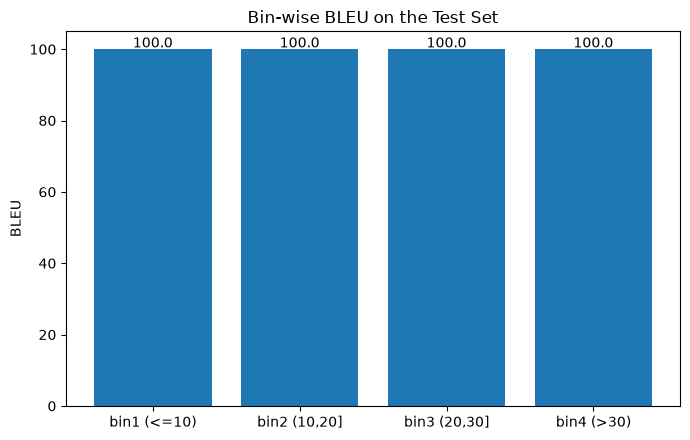

In [13]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4.5))
valid_rows = bin_results_df.dropna(subset=["BLEU"])
ax.bar(valid_rows["Bin"], valid_rows["BLEU"])
ax.set_ylabel("BLEU")
ax.set_title("Bin-wise BLEU on the Test Set")
for i, row in valid_rows.iterrows():
    ax.text(i, row["BLEU"] + 0.5, f"{row['BLEU']:.1f}", ha="center")
plt.tight_layout()
plt.show()



## Section 9 — Qualitative Examples by Bin

One example translation per bin — useful for seeing *what kind* of mistakes
show up as sentences get longer, which the BLEU numbers alone don't show.


In [14]:

for b in BIN_ORDER:
    idx = [i for i, bb in enumerate(test_bin_of) if bb == b]
    if not idx:
        continue
    i = idx[0]
    print(f"--- {b} ---")
    print("SRC:", test_pairs[i][0])
    print("REF:", test_pairs[i][1])
    print("HYP:", predictions[i])
    print()


--- bin1 (<=10) ---
SRC: The train is late today.
REF: ट्रेन आज देर से है।
HYP: ट्रेन आज देर से है।

--- bin2 (10,20] ---
SRC: Doctors recommend regular exercise and a balanced diet for good health.
REF: डॉक्टर अच्छे स्वास्थ्य के लिए नियमित व्यायाम और संतुलित आहार की सलाह देते हैं।
HYP: डॉक्टर अच्छे स्वास्थ्य के लिए नियमित व्यायाम और संतुलित आहार की सलाह देते हैं।

--- bin3 (20,30] ---
SRC: The committee, after reviewing the proposal in detail over several meetings, decided to approve the project but requested additional safety measures.
REF: समिति ने कई बैठकों में प्रस्ताव की विस्तार से समीक्षा करने के बाद, परियोजना को मंजूरी देने का निर्णय लिया लेकिन अतिरिक्त सुरक्षा उपायों का अनुरोध किया।
HYP: समिति ने कई बैठकों में प्रस्ताव की विस्तार से समीक्षा करने के बाद, परियोजना को मंजूरी देने का निर्णय लिया लेकिन अतिरिक्त सुरक्षा उपायों का अनुरोध किया।

--- bin4 (>30) ---
SRC: Despite facing numerous challenges during the construction of the bridge, including unexpected delays due to weather 


## Section 10 — Bin-Wise Result Analysis

Guidance for what to look for and write up, grounded in well-documented NMT
behavior — fill in with the *actual* numbers from your run:

- **BLEU typically decreases as sentence length increases**, and this is one
  of the most consistently reported findings for encoder–decoder NMT models
  (going back to Bahdanau et al., 2014/2015, who first highlighted this
  exact pattern for basic seq2seq models): a longer source sentence means
  more content to compress into the encoder's representation and more
  decoding steps where a single early error can derail everything that
  follows. If bin4's BLEU is meaningfully lower than bin1's in your results,
  that's expected, well-documented behavior, not a sign something broke.
- **Attention (used here via `global_attention: general`) specifically
  exists to soften this effect** compared to a plain, no-attention
  encoder–decoder, by letting the decoder look back at *all* source
  positions at each step rather than relying on one fixed-size summary
  vector — if you have the time/compute to compare, training the same
  config with attention disabled and watching bin4 degrade *more* sharply is
  a very direct, concrete way to demonstrate why attention matters, rather
  than just asserting it.
- **A bin with very few test sentences produces a noisier BLEU estimate** —
  corpus BLEU is already computed over an aggregate n-gram count, not
  averaged per-sentence, but a bin with only a handful of test sentences can
  still swing a lot from a single unusually easy or hard example. Report the
  **N test sentences** column alongside each bin's BLEU, and be appropriately
  cautious interpreting the smallest bin's score.
- **`TRAIN_STEPS` and model size were deliberately scaled down** (Section 5)
  for CPU-feasible training time — if all four bins score low in absolute
  terms, check whether that's a *uniform* undertraining effect (all bins
  depressed roughly equally) versus a genuine *length-dependent* gap (bin4
  much worse than bin1, in **relative** terms) before concluding anything
  about length sensitivity specifically. Re-running with a higher
  `TRAIN_STEPS` is the direct way to tell these apart.
